In [195]:
def add_scale_bar(ax, length_km=50, loc=(0.005, 0.005)):
    """Draw a scale bar of length_km on an Axes whose coordinates are in metres."""
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    x = x0 + loc[0] * (x1 - x0)
    y = y0 + loc[1] * (y1 - y0)
    ax.plot([x, x + length_km * 1000], [y, y], color="black", lw=3)
    ax.text(x + length_km * 500, y + 0.015 * (y1 - y0), f"{length_km} km", ha="center", va="bottom", fontsize=9)


def add_north_arrow(ax, loc=(0.98, 0.95)):
    ax.annotate("N", xy=loc, xytext=(loc[0], loc[1] - 0.1), xycoords="axes fraction",
                ha="center", va="center", fontsize=12, fontweight="bold",
                arrowprops={"arrowstyle": "-|>", "color": "black"})

In [196]:
import geopandas as gpd
import pandas as pd

df=gpd.read_file("../Speculation-Map/Data/Pol/Mean_price.csv")
municipis=gpd.read_file("../Speculation-Map/divisions-administratives-v2r1-municipis-1000000-20250730.json").to_crs(25831)
#municipis.plot()
municipis.head(80)

,CODIMUNI,NOMMUNI,CAPMUNI,AREAM5000,CODICOMAR,NOMCOMAR,CAPCOMAR,CODIVEGUE,NOMVEGUE,CAPVEGUE,CODIPROV,NOMPROV,CAPPROV,geometry
0,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,08,Barcelona,Barcelona,"MULTIPOLYGON (((410315.774 4598888.867, 410075..."
1,080023,Aguilar de Segarra,Aguilar de Segarra,43.2198,07,Bages,Manresa,07,Catalunya Central,*,08,Barcelona,Barcelona,"MULTIPOLYGON (((385155.598 4625034.944, 384697..."
2,080039,Alella,Alella,9.6346,21,Maresme,Mataró,01,Barcelona,Barcelona,08,Barcelona,Barcelona,"MULTIPOLYGON (((440348.026 4596213.927, 440338..."
3,080044,Alpens,Alpens,13.7788,43,Lluçanès,Prats de Lluçanès,07,Catalunya Central,*,08,Barcelona,Barcelona,"MULTIPOLYGON (((425142.962 4665930.715, 424829..."
4,080057,l'Ametlla del Vallès,l'Ametlla del Vallès,14.0885,41,Vallès Oriental,Granollers,01,Barcelona,Barcelona,08,Barcelona,Barcelona,"MULTIPOLYGON (((436871.133 4617049.619, 436914..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75,080765,Esparreguera,Esparreguera,27.3013,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,08,Barcelona,Barcelona,"MULTIPOLYGON (((405449.802 4605030.623, 405262..."
76,080771,Esplugues de Llobregat,Esplugues de Llobregat,4.5114,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,08,Barcelona,Barcelona,"MULTIPOLYGON (((424496.159 4582929.783, 424491..."
77,080787,l'Espunyola,l'Espunyola,35.6840,14,Berguedà,Berga,07,Catalunya Central,*,08,Barcelona,Barcelona,"MULTIPOLYGON (((390705.31 4654908.731, 390723...."
78,080790,l'Estany,l'Estany,10.2438,42,Moianès,Moià,07,Catalunya Central,*,08,Barcelona,Barcelona,"MULTIPOLYGON (((425539.787 4637727.184, 425195..."


In [197]:
df["Renda"]

0        783,62
1        384,29
2        474,23
3              
4        688,46
          ...  
47536          
47537          
47538          
47539          
47540    268,57
Name: Renda, Length: 47541, dtype: str

In [198]:
def string_to_float(s):
    return pd.to_numeric(s.astype(str)
    .str.replace('.', '', regex=False)
    .str.replace(',', '.', regex=False), errors='coerce')
    

In [199]:
cols = ['Renda', 'Habitatges']
df[cols] = df[cols].apply(string_to_float)

In [200]:
df["Renda"]

0        783.62
1        384.29
2        474.23
3           NaN
4        688.46
          ...  
47536       NaN
47537       NaN
47538       NaN
47539       NaN
47540    268.57
Name: Renda, Length: 47541, dtype: float64

In [201]:
def string_to_float_2(s):
    return pd.to_numeric(s
    , errors='coerce')

In [269]:
habitants=gpd.read_file("../Speculation-Map/Data/aaaaa.csv")

habitants["value"]=habitants["value"].apply(string_to_float_2)

total_hab_mun=habitants.groupby("MUN",as_index=False).agg(inhabitants=("value", lambda s: s.sum()/2))
total_hab_mun["ine5"]=total_hab_mun["MUN"].str[:5]

total_hab_com_1=total_hab_mun.merge(municipis[["ine5","CODICOMAR"]],on="ine5",how="left",validate="many_to_one")
total_hab_com_2=total_hab_com_1.groupby("CODICOMAR",as_index=False).agg(inhab_com=("inhabitants",lambda s: s.sum()))
total_hab_com=municipis.merge(total_hab_com_2,on="CODICOMAR",how="left",validate="many_to_one")

total_hab_com

,CODIMUNI,NOMMUNI,CAPMUNI,AREAM5000,CODICOMAR,NOMCOMAR,CAPCOMAR,CODIVEGUE,NOMVEGUE,CAPVEGUE,CODIPROV,NOMPROV,CAPPROV,geometry,ine5,inhab_com
0,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,08,Barcelona,Barcelona,"MULTIPOLYGON (((410315.774 4598888.867, 410075...",08001,856867.0
1,080023,Aguilar de Segarra,Aguilar de Segarra,43.2198,07,Bages,Manresa,07,Catalunya Central,*,08,Barcelona,Barcelona,"MULTIPOLYGON (((385155.598 4625034.944, 384697...",08002,187620.0
2,080039,Alella,Alella,9.6346,21,Maresme,Mataró,01,Barcelona,Barcelona,08,Barcelona,Barcelona,"MULTIPOLYGON (((440348.026 4596213.927, 440338...",08003,477375.0
3,080044,Alpens,Alpens,13.7788,43,Lluçanès,Prats de Lluçanès,07,Catalunya Central,*,08,Barcelona,Barcelona,"MULTIPOLYGON (((425142.962 4665930.715, 424829...",08004,5723.0
4,080057,l'Ametlla del Vallès,l'Ametlla del Vallès,14.0885,41,Vallès Oriental,Granollers,01,Barcelona,Barcelona,08,Barcelona,Barcelona,"MULTIPOLYGON (((436871.133 4617049.619, 436914...",08005,428782.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
942,439039,Camarles,Camarles,30.0157,09,Baix Ebre,Tortosa,05,Terres de l'Ebre,Tortosa,43,Tarragona,Tarragona,"MULTIPOLYGON (((301288.757 4521580.722, 301179...",43903,84077.0
943,439044,l'Aldea,l'Aldea,30.4743,09,Baix Ebre,Tortosa,05,Terres de l'Ebre,Tortosa,43,Tarragona,Tarragona,"MULTIPOLYGON (((298373.126 4520080.954, 298283...",43904,84077.0
944,439057,Salou,Salou,15.1248,36,Tarragonès,Tarragona,04,Camp de Tarragona,Tarragona,43,Tarragona,Tarragona,"MULTIPOLYGON (((343971.449 4551180.512, 343522...",43905,279332.0
945,439060,l'Ampolla,l'Ampolla,35.6196,09,Baix Ebre,Tortosa,05,Terres de l'Ebre,Tortosa,43,Tarragona,Tarragona,"MULTIPOLYGON (((305434.379 4524718.838, 305365...",43906,84077.0


947 947


,CODIMUNI,NOMMUNI,CAPMUNI,AREAM5000,CODICOMAR,NOMCOMAR,CAPCOMAR,CODIVEGUE,NOMVEGUE,CAPVEGUE,CODIPROV,NOMPROV,CAPPROV,geometry,ine5,renda,habitatges,habit_per_inhab
0,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,08,Barcelona,Barcelona,"MULTIPOLYGON (((410315.774 4598888.867, 410075...",08001,797.772497,196,0.000229
1,080023,Aguilar de Segarra,Aguilar de Segarra,43.2198,07,Bages,Manresa,07,Catalunya Central,*,08,Barcelona,Barcelona,"MULTIPOLYGON (((385155.598 4625034.944, 384697...",08002,467.837529,65,0.000346
2,080039,Alella,Alella,9.6346,21,Maresme,Mataró,01,Barcelona,Barcelona,08,Barcelona,Barcelona,"MULTIPOLYGON (((440348.026 4596213.927, 440338...",08003,856.524301,147,0.000308
3,080044,Alpens,Alpens,13.7788,43,Lluçanès,Prats de Lluçanès,07,Catalunya Central,*,08,Barcelona,Barcelona,"MULTIPOLYGON (((425142.962 4665930.715, 424829...",08004,449.935368,5,0.000874
4,080057,l'Ametlla del Vallès,l'Ametlla del Vallès,14.0885,41,Vallès Oriental,Granollers,01,Barcelona,Barcelona,08,Barcelona,Barcelona,"MULTIPOLYGON (((436871.133 4617049.619, 436914...",08005,725.139230,86,0.000201
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
165,081666,la Pobla de Lillet,la Pobla de Lillet,51.5344,14,Berguedà,Berga,07,Catalunya Central,*,08,Barcelona,Barcelona,"MULTIPOLYGON (((412989.788 4679090.918, 412570...",08166,405.861248,17,0.000409
166,081672,Polinyà,Polinyà,8.9952,40,Vallès Occidental,Sabadell / Terrassa,01,Barcelona,Barcelona,08,Barcelona,Barcelona,"MULTIPOLYGON (((429181.483 4602928.005, 429132...",08167,734.131677,341,0.000351
167,081688,Pontons,Pontons,25.7726,03,Alt Penedès,Vilafranca del Penedès,08,Penedès,*,08,Barcelona,Barcelona,"MULTIPOLYGON (((377872.654 4588649.93, 377754....",08168,571.578352,36,0.000310
168,081691,el Prat de Llobregat,el Prat de Llobregat,33.4473,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,08,Barcelona,Barcelona,"MULTIPOLYGON (((422566.578 4577772.77, 422522....",08169,797.772497,196,0.000229


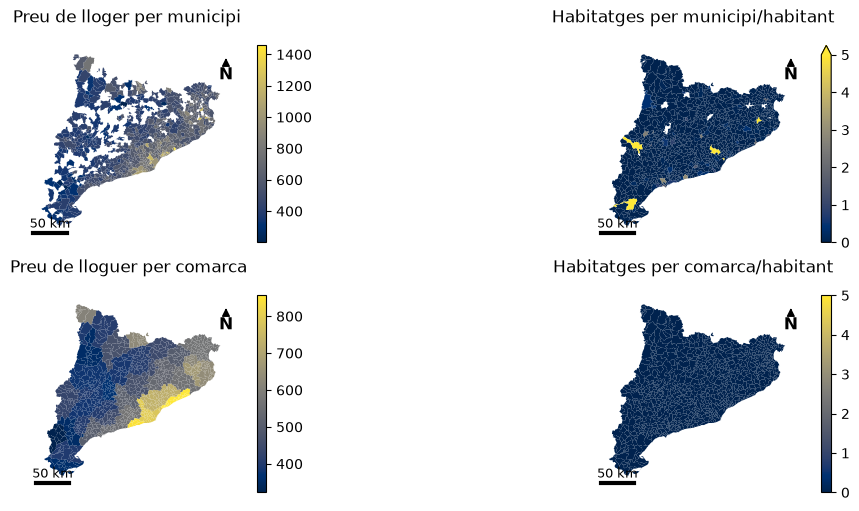

In [279]:
code_municipi=df["Codi territorial"]
mean_rent=df["Renda"]
number_rents=df["Habitatges"]

# The municipality code is not the same in both data sets. In the map coordinates, the code is 6 digits long
# (the sixth digit is a check digit). In the mean price data, the code is five digits long (INE 5). We take out the check digit
# from the map coordinates set and then merge the dataset using the municipality code.

municipis["ine5"]=municipis["CODIMUNI"].str[:5]
df["ine5"]=df["Codi territorial"]

############################################################## INHABITANTS

habitants=gpd.read_file("../Speculation-Map/Data/aaaaa.csv")

habitants["value"]=habitants["value"].apply(string_to_float_2)

total_hab_mun=habitants.groupby("MUN",as_index=False).agg(inhabitants=("value", lambda s: s.sum()/2))
total_hab_mun["ine5"]=total_hab_mun["MUN"].str[:5]

total_hab_com_1=total_hab_mun.merge(municipis[["ine5","CODICOMAR"]],on="ine5",how="left",validate="many_to_one")
total_hab_com_2=total_hab_com_1.groupby("CODICOMAR",as_index=False).agg(inhab_com=("inhabitants",lambda s: s.sum()))
total_hab_com=municipis.merge(total_hab_com_2,on="CODICOMAR",how="left",validate="many_to_one")

###############################################################

df_2026=df[df["Any"]=="2026"]
df_2026_mean=df.groupby("ine5",as_index=False).agg(renda_2026=("Renda", lambda s: s.mean()))
df_26=df.merge(df_2026_mean,on="ine5",how="left",validate="many_to_one")


per_municipi_2026=df_26.groupby("ine5",as_index=False).agg(renda=("Renda", lambda s: s.mean()) ,habitatges=("Habitatges", lambda s: s.mean() ))
per_municipi_2026["habitatges"]=per_municipi_2026["habitatges"].astype(int)
merged_municipi_2026=municipis.merge(per_municipi_2026,on="ine5",how="left",validate="one_to_one")

merged_municipi_2026["habit_per_inhab"]=merged_municipi_2026["habitatges"]/total_hab_mun["inhabitants"]


df_comarca=df_26.merge(municipis[["ine5","CODICOMAR"]],on="ine5",how="left",validate="many_to_one")

per_comarca_2026 = df_comarca.groupby("CODICOMAR", as_index=False).agg(renda=("Renda", lambda s: s.mean() ),habitatges=("Habitatges", lambda s: s.mean() ))
per_comarca_2026["habitatges"]=per_comarca_2026["habitatges"].astype(int)

merged_comarca_2026=municipis.merge(per_comarca_2026,on="CODICOMAR",how="left",validate="many_to_one")
print(len(merged_comarca_2026["renda"]),len(total_hab_com["inhab_com"]))

merged_comarca_2026["habit_per_inhab"]=merged_comarca_2026["habitatges"]/total_hab_com["inhab_com"]


fig, axs = plt.subplots(2,2,figsize=(11, 5), layout="constrained")

merged_municipi_2026.plot(column="renda",cmap="cividis",legend=True,ax=axs[0][0])
merged_municipi_2026.plot(column="habit_per_inhab",cmap="cividis",vmin=0,vmax=5,legend=True,ax=axs[0][1])
merged_comarca_2026.plot(column="renda",cmap="cividis",legend=True,ax=axs[1][0])
merged_comarca_2026.plot(column="habit_per_inhab",cmap="cividis",vmin=0,vmax=5,legend=True,ax=axs[1][1])

axs[0][0].set_title("Preu de lloger per municipi")
axs[0][1].set_title("Habitatges per municipi/habitant")
axs[1][0].set_title("Preu de lloguer per comarca")
axs[1][1].set_title("Habitatges per comarca/habitant")

for i in axs:
    for ax in i:
        ax.set_axis_off()
        add_scale_bar(ax)
        add_north_arrow(ax)


merged_comarca_2026.head(170)

In [147]:
df_2026=df[df["Any"]=="2026"]
df_2026_mean=df.groupby("ine5",as_index=False).agg(renda_2026=("Renda", lambda s: s.mean()))
df_2026_mean

,ine5,renda_2026
0,08001,684.226094
1,08002,NaN
2,08003,1208.400469
3,08004,327.590000
4,08005,990.379062
...,...,...
940,43903,399.181852
941,43904,354.047344
942,43905,563.673175
943,43906,477.537187


/Users/polramosrodriguez/opt/anaconda3/envs/ub-bigdata-viz/lib/python3.12/site-packages/geopandas/plotting.py:1339: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  ax.figure.canvas.draw_idle()


,CODIMUNI,NOMMUNI,CAPMUNI,AREAM5000,CODICOMAR,NOMCOMAR,CAPCOMAR,CODIVEGUE,NOMVEGUE,CAPVEGUE,...,geometry,ine5,Àmbit territorial,Codi territorial,Nom territori,Any,Període,Habitatges,Renda,Tram de preus
0,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,...,"MULTIPOLYGON (((1.92486 41.53663, 1.92197 41.5...",08001,Municipi,08001,Abrera,2026,gener-juny,62,"783,62",> 600 euros/mes
1,080023,Aguilar de Segarra,Aguilar de Segarra,43.2198,07,Bages,Manresa,07,Catalunya Central,*,...,"MULTIPOLYGON (((1.61829 41.76885, 1.61278 41.7...",08002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,080039,Alella,Alella,9.6346,21,Maresme,Mataró,01,Barcelona,Barcelona,...,"MULTIPOLYGON (((2.28512 41.51534, 2.28501 41.5...",08003,Municipi,08003,Alella,2026,gener-juny,50,"1.698,03",> 600 euros/mes
3,080044,Alpens,Alpens,13.7788,43,Lluçanès,Prats de Lluçanès,07,Catalunya Central,*,...,"MULTIPOLYGON (((2.09411 42.14192, 2.09031 42.1...",08004,Municipi,08004,Alpens,2026,gener-juny,1,,> 600 euros/mes
4,080057,l'Ametlla del Vallès,l'Ametlla del Vallès,14.0885,41,Vallès Oriental,Granollers,01,Barcelona,Barcelona,...,"MULTIPOLYGON (((2.24126 41.70273, 2.24178 41.7...",08005,Municipi,08005,"Ametlla del Vallès, l'",2026,gener-juny,33,"1.061,53",> 600 euros/mes
5,080060,Arenys de Mar,Arenys de Mar,6.4836,21,Maresme,Mataró,01,Barcelona,Barcelona,...,"MULTIPOLYGON (((2.56702 41.59559, 2.5637 41.59...",08006,Municipi,08006,Arenys de Mar,2026,gener-juny,124,"825,39",> 600 euros/mes
6,080076,Arenys de Munt,Arenys de Munt,21.6815,21,Maresme,Mataró,01,Barcelona,Barcelona,...,"MULTIPOLYGON (((2.53683 41.64136, 2.53684 41.6...",08007,Municipi,08007,Arenys de Munt,2026,gener-juny,44,"881,94",> 600 euros/mes
7,080082,Argençola,Argençola,47.3814,06,Anoia,Igualada,08,Penedès,*,...,"MULTIPOLYGON (((1.45016 41.63563, 1.44891 41.6...",08008,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,080095,Argentona,Argentona,25.3281,21,Maresme,Mataró,01,Barcelona,Barcelona,...,"MULTIPOLYGON (((2.37839 41.59357, 2.3751 41.59...",08009,Municipi,08009,Argentona,2026,gener-juny,57,"1.021,20",> 600 euros/mes
9,080109,Artés,Artés,17.8445,07,Bages,Manresa,07,Catalunya Central,*,...,"MULTIPOLYGON (((1.96539 41.81485, 1.96299 41.8...",08010,Municipi,08010,Artés,2026,gener-juny,37,"535,69",> 450 i <= 600 euros/mes


/Users/polramosrodriguez/opt/anaconda3/envs/ub-bigdata-viz/lib/python3.12/site-packages/IPython/core/events.py:101: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  func(*args, **kwargs)
/Users/polramosrodriguez/opt/anaconda3/envs/ub-bigdata-viz/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


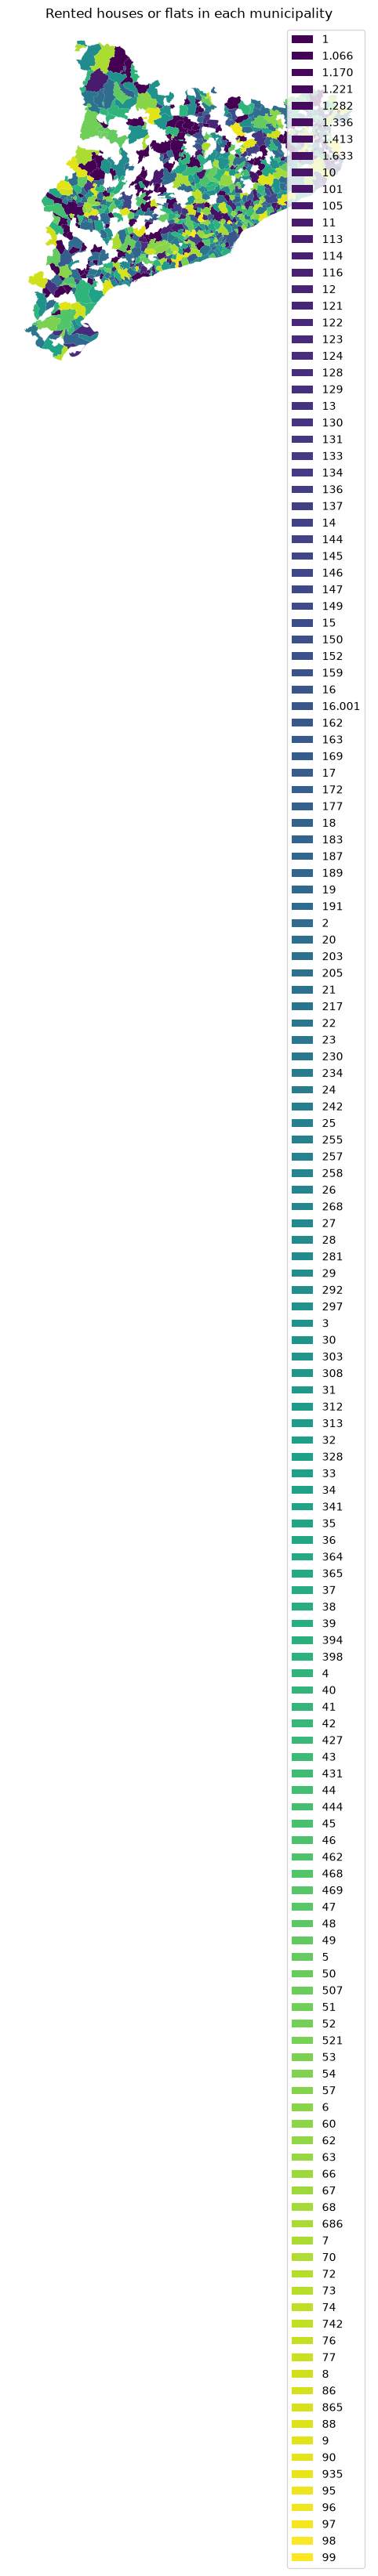

In [17]:
import matplotlib.pyplot as plt

code_municipi=df["Codi territorial"]
mean_rent=df["Renda"]
number_rents=df["Habitatges"]

# The municipality code is not the same in both data sets. In the map coordinates, the code is 6 digits long
# (the sixth digit is a check digit). In the mean price data, the code is five digits long (INE 5). We take out the check digit
# from the map coordinates set and then merge the dataset using the municipality code.

municipis["ine5"]=municipis["CODIMUNI"].str[:5]
df["ine5"]=df["Codi territorial"]

#mean_rent_2026=df.groupby("ine5",as_index=False).agg(renda=("Renda", lambda s: s.sum() ))
mean_rent_2026= df[df["Any"] == "2026"]
mean_rent_mes=mean_rent_2026[mean_rent_2026["Període"]=="gener-juny"]
merged_mes = municipis.merge(mean_rent_mes, on="ine5", how="left", validate="one_to_one")
merged_mes["Habitatges"]=merged_mes["Habitatges"].replace(".","")
#merged_mes["Habitatges"]=merged_mes["Habitatges"].astype(float)

fig, axs = plt.subplots(1,1,figsize=(11, 5), layout="constrained")

merged_mes.plot(column="Habitatges",cmap="viridis",legend=True,ax=axs)

axs.set_title("Rented houses or flats in each municipality")
axs.set_axis_off()
#add_scale_bar(axs)
#add_north_arrow(axs)


merged_mes.head(50)